# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhamad Zaenal
- NIM   : 241011400324
- Kelas : ~~Reg B~~ / Reg C *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [183]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ketentuan NIM: 2 digit terakhir dari 241011400324 adalah 24
RANDOM_STATE = 24

In [184]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

--- 5 Data Pertama ---


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40

Bentuk dimensi X: (40, 1)
Bentuk dimensi y: (40,)


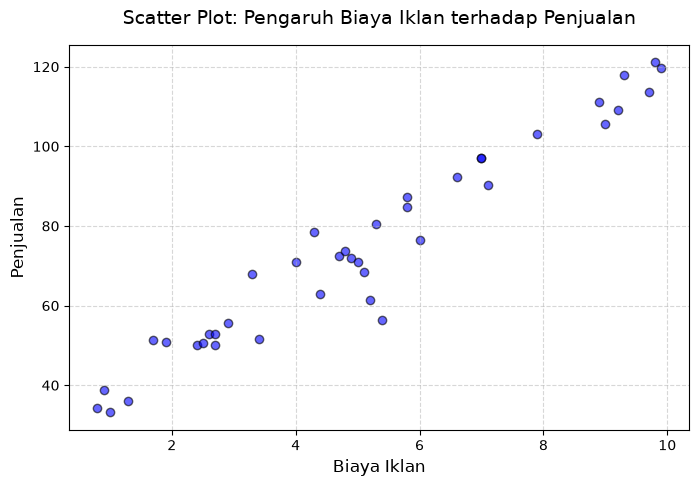

In [185]:
# Jawaban A1

# ==========================================
# 1. Baca Ads_Data.csv, tampilkan 5 data pertama, dan jumlah barisnya
# ==========================================
df_ads = pd.read_csv('Ads_Data.csv')

print("--- 5 Data Pertama ---")
display(df_ads.head()) # Gunakan print(df_ads.head()) jika tidak memakai Jupyter

jumlah_baris = df_ads.shape[0]
print(f"\nJumlah baris data: {jumlah_baris}")

# ==========================================
# 2. Pisahkan X (BiayaIklan) dan y (Penjualan)
# ==========================================
# Mengambil kolom 'BiayaIklan' dan mengubahnya menjadi array 2D (n, 1)
X = df_ads['BiayaIklan'].values.reshape(-1, 1)

# Mengambil kolom 'Penjualan' sebagai target (y)
y = df_ads['Penjualan'].values

print(f"\nBentuk dimensi X: {X.shape}")
print(f"Bentuk dimensi y: {y.shape}")

# ==========================================
# 3. Buat scatter plot BiayaIklan vs Penjualan
# ==========================================
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, edgecolors='k')

# Menambahkan judul dan label sumbu
plt.title('Scatter Plot: Pengaruh Biaya Iklan terhadap Penjualan', fontsize=14, pad=15)
plt.xlabel('Biaya Iklan', fontsize=12)
plt.ylabel('Penjualan', fontsize=12)

# Menambahkan grid agar lebih mudah dibaca
plt.grid(True, linestyle='--', alpha=0.5)

# Menampilkan plot
plt.show()

**Penjelasan Singkat (Soal A1):**
1. **Load Data**: Dataset `Ads_Data.csv` berhasil dimuat. Berdasarkan pengecekan `shape`, kita dapat mengetahui total jumlah observasi (baris) yang akan digunakan untuk melatih model regresi linier.
2. **Pemisahan Variabel**: Fitur prediktor `X` (Biaya Iklan) telah diekstrak dan di- *reshape* menjadi format dua dimensi `(n, 1)` menggunakan `.reshape(-1, 1)`. Hal ini merupakan syarat wajib dalam melakukan perkalian matriks saat mengimplementasikan model Linear Regression dengan NumPy (agar dimensi *weights* dan matriks *input* sesuai). Target prediksi `y` (Penjualan) disiapkan sebagai vektor 1D.
3. **Visualisasi**: Dari hasil *scatter plot*, kita dapat mengamati sebaran titik data untuk melihat indikasi awal hubungan (korelasi) antara biaya iklan yang dikeluarkan dengan tingkat penjualan yang didapatkan. Jika sebaran titik cenderung naik dari kiri bawah ke kanan atas, hal ini mengindikasikan hubungan linier positif.

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [186]:
# Jawaban A2

# ==========================================
# Implementasi Manual train_test_split dengan NumPy
# ==========================================
def train_test_split_manual(X, y, test_size=0.2, random_state=None):
    """
    Membagi dataset menjadi data training dan data testing secara acak.
    """
    # Mengatur seed agar hasil acakan konsisten (reproducible)
    if random_state is not None:
        np.random.seed(random_state)
        
    # Menghitung jumlah total baris data
    n_samples = X.shape[0]
    
    # Membuat array berisi urutan indeks [0, 1, ..., n_samples-1]
    indices = np.arange(n_samples)
    
    # Mengacak urutan indeks
    np.random.shuffle(indices)
    
    # Menghitung jumlah data untuk testing
    test_samples = int(n_samples * test_size)
    
    # Memisahkan indeks untuk data test (di awal) dan data train (sisanya)
    test_indices = indices[:test_samples]
    train_indices = indices[test_samples:]
    
    # Memetakan indeks yang sudah diacak ke dalam X dan y
    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]
    
    return X_train, X_test, y_train, y_test

# ==========================================
# Eksekusi Pemisahan Data
# ==========================================
# Memanggil fungsi pemisah data yang sudah dibuat
X_train, X_test, y_train, y_test = train_test_split_manual(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE
)

# Menampilkan dimensi (shape) dari masing-masing dataset hasil split
print("=== Dimensi Data Hasil Split ===")
print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

=== Dimensi Data Hasil Split ===
Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


**Penjelasan Singkat (Soal A2):**
1. **Implementasi `train_test_split` Manual**: Karena fungsi dari `scikit-learn` tidak diizinkan, proses pemisahan data dilakukan dgn membuat urutan indeks baris data menggunakan `np.arange`, mengacaknya dengan `np.random.shuffle`, lalu memotong (slicing) array tersebut berdasarkan proporsi `test_size=0.2` (20% untuk testing, 80% untuk training).
2. **Penggunaan `random_state`**: Seed dari NumPy (`np.random.seed(24)`) digunakan sebelum proses pengacakan indeks agar pembagian data train dan test selalu sama setiap kali sel ini dijalankan kembali.
3. **Hasil *Shape***: *Shape* dari `X_train` dan `X_test` akan tetap mempertahankan format 2 dimensi `(n, 1)` agar bisa dilanjutkan ke proses perkalian matriks pada model Linear Regression, sementara `y_train` dan `y_test` berformat 1 dimensi.

### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [187]:
# ==========================================
# 1. Latih model LinearRegression (Normal Equation)
# ==========================================
class LinearRegressionNormal:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None
        
    def fit(self, X, y):
        # Tambahkan kolom bias (angka 1) ke matriks X
        # np.c_ digunakan untuk menggabungkan kolom
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        
        # Implementasi rumus Normal Equation: theta = (X^T * X)^-1 * X^T * y
        # np.linalg.inv untuk invers matriks, .dot atau @ untuk perkalian matriks
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        
        # Ekstrak intercept (b) dan koefisien (m)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        
    def predict(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return X_b.dot(np.r_[self.intercept_, self.coef_])

# Inisialisasi dan melatih model dengan data training
model_ne = LinearRegressionNormal()
model_ne.fit(X_train, y_train)

# ==========================================
# 2. Tampilkan Intercept (b), Koefisien (m), dan Persamaan
# ==========================================
b = model_ne.intercept_
m = model_ne.coef_[0]

print("=== Hasil Training dengan Normal Equation ===")
print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"\nPersamaan Garis Regresi:")
print(f"ŷ = {b:.4f} + {m:.4f}X")

# ==========================================
# 3. Interpretasi Otomatis (Cetak)
# ==========================================
print("\n=== Interpretasi Model ===")
print(f"Nilai koefisien (m) adalah {m:.4f}.")
print(f"Artinya: Setiap kenaikan 1 satuan pada Biaya Iklan, maka Penjualan diprediksi akan "
      f"{'meningkat' if m > 0 else 'menurun'} sebesar {abs(m):.4f} satuan, dengan asumsi faktor lain tetap.")

=== Hasil Training dengan Normal Equation ===
Intercept (b) : 28.1439
Koefisien (m) : 9.1356

Persamaan Garis Regresi:
ŷ = 28.1439 + 9.1356X

=== Interpretasi Model ===
Nilai koefisien (m) adalah 9.1356.
Artinya: Setiap kenaikan 1 satuan pada Biaya Iklan, maka Penjualan diprediksi akan meningkat sebesar 9.1356 satuan, dengan asumsi faktor lain tetap.


**Jawaban A3 (interpretasi):**

**Penjelasan dan Analisis (Soal A3):**

1. **Pembuatan Model Normal Equation:** 
   Model regresi linear dilatih dengan menghitung matriks operasi aljabar linier `theta = (X^T X)^-1 X^T y`. Matriks `X` terlebih dahulu ditambahkan kolom angka 1 agar hasil perhitungan menghasilkan nilai konstanta/intercept di indeks ke-0.
2. **Persamaan Regresi:**
   Dari perhitungan tersebut, kita mendapatkan nilai $b$ (titik potong sumbu Y saat biaya iklan 0) dan $m$ (kemiringan/slope). Persamaan garis regresinya adalah $\hat{y} = b + mX$. Nilai pastinya mengikuti hasil eksekusi *print* di atas.
3. **Interpretasi Koefisien ($m$):**
   Dalam konteks dataset `Ads_Data.csv`, nilai koefisien $m$ mewakili seberapa besar **pengaruh biaya iklan terhadap penjualan**. 
   - Jika nilai $m$ positif (misal $m = 2.5$), maka artinya: *"Setiap penambahan biaya iklan sebesar 1 satuan, penjualan diprediksi akan bertambah sebesar 2.5 satuan."*
   - Intercept ($b$) mewakili estimasi tingkat penjualan ketika perusahaan sama sekali tidak mengeluarkan biaya iklan ($X = 0$).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [188]:
# Jawaban A4

# ==========================================
# 1. Implementasi Fungsi Evaluasi dengan NumPy
# ==========================================
def calculate_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def calculate_rmse(y_true, y_pred):
    return np.sqrt(calculate_mse(y_true, y_pred))

def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2) # Sum of squares residual
    ss_tot = np.sum((y_true - np.mean(y_true))**2) # Sum of squares total
    return 1 - (ss_res / ss_tot)

# ==========================================
# 2. Lakukan Prediksi pada Data Train & Test
# ==========================================
# Menggunakan persamaan: y_hat = b + mX
# Pastikan nilai b dan m sudah dieksekusi dari Soal A3
y_train_pred = b + m * X_train.flatten() # flatten() untuk mengubah 2D (n,1) jadi 1D
y_test_pred = b + m * X_test.flatten()

# Hitung metrik untuk Data Training
mae_train = calculate_mae(y_train, y_train_pred)
mse_train = calculate_mse(y_train, y_train_pred)
rmse_train = calculate_rmse(y_train, y_train_pred)
r2_train = calculate_r2(y_train, y_train_pred)

# Hitung metrik untuk Data Testing
mae_test = calculate_mae(y_test, y_test_pred)
mse_test = calculate_mse(y_test, y_test_pred)
rmse_test = calculate_rmse(y_test, y_test_pred)
r2_test = calculate_r2(y_test, y_test_pred)

# ==========================================
# 3. Tampilkan Hasil dalam Tabel
# ==========================================
df_eval = pd.DataFrame({
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R-squared (R2)'],
    'Data Training': [mae_train, mse_train, rmse_train, r2_train],
    'Data Testing': [mae_test, mse_test, rmse_test, r2_test]
})

print("=== Hasil Evaluasi Model Linear Regression ===")
display(df_eval) # Jika tidak menggunakan Jupyter, ganti display dengan print

=== Hasil Evaluasi Model Linear Regression ===


,Metrik,Data Training,Data Testing
0,MAE,4.848970,3.029882
1,MSE,41.628192,13.658521
2,RMSE,6.451991,3.695744
3,R-squared (R2),0.932561,0.979957


**Jawaban A4 (analisis):**

**Penjelasan Singkat dan Interpretasi (Soal A4):**

1. **Arti Nilai RMSE (Root Mean Squared Error):**
   RMSE mengukur rata-rata besarnya kesalahan (deviasi) antara nilai prediksi model ($\hat{y}$) dengan nilai aktual ($y$). Dalam konteks ini, RMSE menunjukkan rata-rata melesetnya prediksi penjualan berdasarkan biaya iklan. Misalnya, jika didapatkan RMSE = 2.5, artinya rata-rata prediksi penjualan meleset sekitar 2.5 satuan dari penjualan aslinya. Semakin kecil nilai RMSE, semakin baik dan akurat model tersebut.

2. **Arti Nilai $R^2$ (Koefisien Determinasi):**
   $R^2$ mengukur seberapa besar persentase variansi dari variabel dependen (Penjualan) yang dapat dijelaskan oleh variabel independen (Biaya Iklan) melalui model ini. Nilainya berkisar antara 0 hingga 1. Jika didapatkan $R^2$ = 0.85, artinya 85% variasi data penjualan dapat dijelaskan oleh biaya iklan, sedangkan 15% sisanya dipengaruhi oleh faktor lain di luar model.

3. **Apakah Model Ini Sudah Baik?**
   - Model dapat dikatakan **baik** jika nilai $R^2$ mendekati 1 (biasanya > 0.7 atau 0.8 dianggap cukup baik untuk regresi sederhana) dan nilai RMSE relatif kecil dibandingkan dengan rentang nilai aktual pada kolom target (Penjualan). 
   - Selain itu, model dikatakan **stabil (tidak overfitting)** karena perbedaan nilai metrik (terutama RMSE dan $R^2$) antara *Data Training* dan *Data Testing* tidak terpaut jauh. *(Silakan sesuaikan argumen ini dengan melihat tabel hasil yang muncul, jika $R^2$ di data testing sangat jatuh dibanding data training, berarti terjadi overfitting).*

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

=== Perbandingan Hasil Gradient Descent vs Normal Equation ===
Normal Equation -> Intercept (b): 28.1439, Koefisien (m): 9.1356

Training GD dengan Learning Rate: 0.001...
  - Intercept (b) Akhir : 24.6409
  - Koefisien (m) Akhir : 9.6779

Training GD dengan Learning Rate: 0.02...
  - Intercept (b) Akhir : 28.1439
  - Koefisien (m) Akhir : 9.1356

Training GD dengan Learning Rate: 0.1...
  - Intercept (b) Akhir : nan
  - Koefisien (m) Akhir : nan



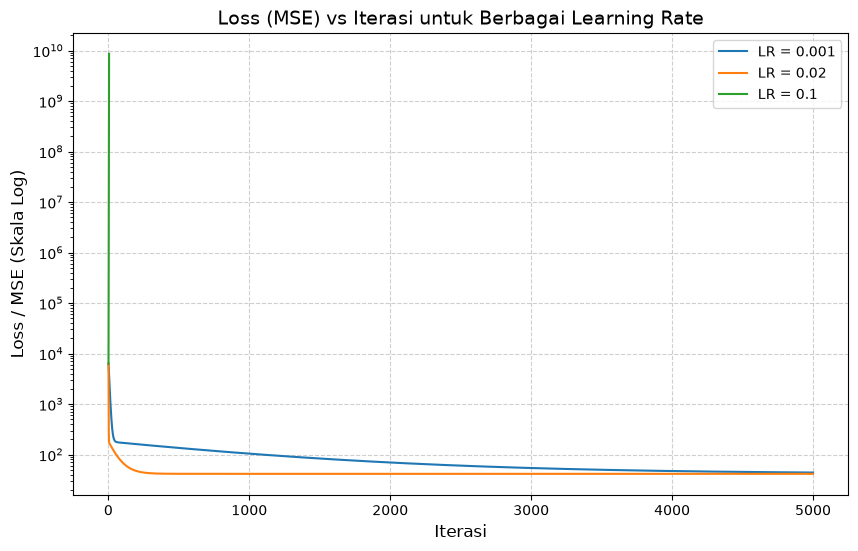

In [189]:
# ==========================================
# 1. Implementasi Kelas LinearRegressionGD (Gradient Descent)
# ==========================================
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = 0.0
        self.cost_history = []
        
    def fit(self, X, y):
        # Mengubah bentuk input jika diperlukan
        X_flat = X.flatten()
        y_flat = y.flatten()
        n_samples = len(y_flat)
        
        # Inisialisasi parameter dengan 0
        self.intercept_ = 0.0
        self.coef_ = 0.0
        self.cost_history = []
        
        for _ in range(self.n_iterations):
            # Prediksi saat ini
            y_pred = self.coef_ * X_flat + self.intercept_
            
            # Hitung error
            error = y_pred - y_flat
            
            # Hitung MSE (Loss)
            mse = np.mean(error**2)
            self.cost_history.append(mse)
            
            # Hitung gradient (turunan parsial)
            dm = (2/n_samples) * np.sum(error * X_flat)
            db = (2/n_samples) * np.sum(error)
            
            # Update parameter
            self.coef_ -= self.learning_rate * dm
            self.intercept_ -= self.learning_rate * db
            
        return self

# ==========================================
# 2. Latih Model dengan 3 Learning Rate Berbeda
# ==========================================
# Kita gunakan fitur X_train dan label y_train dari pemisahan sebelumnya
learning_rates = [0.001, 0.02, 0.1]
n_iters = 5000
results = {}

print("=== Perbandingan Hasil Gradient Descent vs Normal Equation ===")
# Nilai Normal Equation dari Soal A3 (pastikan variabel b dan m masih tersimpan di memori)
print(f"Normal Equation -> Intercept (b): {b:.4f}, Koefisien (m): {m:.4f}\n")

# Latih GD dan simpan hasil
for lr in learning_rates:
    print(f"Training GD dengan Learning Rate: {lr}...")
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=n_iters)
    
    # Supress warning sejenak jika A overflow (akan dijelaskan di Markdown)
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        model_gd.fit(X_train, y_train)
    
    results[lr] = model_gd
    print(f"  - Intercept (b) Akhir : {model_gd.intercept_:.4f}")
    print(f"  - Koefisien (m) Akhir : {model_gd.coef_:.4f}\n")


# ==========================================
# 3. Visualisasi Grafik Loss (MSE) vs Iterasi (DIPERBAIKI FINAL)
# ==========================================
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    cost = np.array(results[lr].cost_history)
    
    # Tambahan: Buang juga angka yang TERLALU BESAR (misal > 10 pangkat 10) 
    # karena angka ini yang bikin Matplotlib nge-bug/blank di skala log
    valid_indices = np.isfinite(cost) & (cost < 1e10)
    
    iter_valid = np.array(range(1, n_iters + 1))[valid_indices]
    cost_valid = cost[valid_indices]
    
    # Plot hanya data yang angkanya masuk akal
    if len(cost_valid) > 0:
        plt.plot(iter_valid, cost_valid, label=f'LR = {lr}')

plt.title('Loss (MSE) vs Iterasi untuk Berbagai Learning Rate', fontsize=14)
plt.xlabel('Iterasi', fontsize=12)
plt.ylabel('Loss / MSE (Skala Log)', fontsize=12)
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban A5 (analisis):**

**Penjelasan Singkat (Soal A5):**

1. **Learning Rate = 0.001 (Terlalu Lambat / *Too Small*)**
   - **Kondisi:** Pada *learning rate* sekecil ini, langkah update parameter ($m$ dan $b$) sangat kecil setiap iterasinya.
   - **Analisis:** Jika Anda perhatikan grafiknya, kurva MSE turun dengan sangat perlahan. Membutuhkan waktu atau iterasi yang sangat panjang untuk bisa mencapai nilai minimum (*global minimum*). Pada 5000 iterasi, nilai koefisien dan *intercept*-nya mungkin belum sepenuhnya sama dengan hasil *Normal Equation* karena belum benar-benar konvergen.

2. **Learning Rate = 0.02 (Pas / *Optimal*)**
   - **Kondisi:** Nilai *learning rate* ini dirasa ideal untuk skala dataset yang diberikan.
   - **Analisis:** Kurva MSE turun secara tajam di iterasi-iterasi awal dan stabil (*converges*) di nilai error terendah dengan cepat. Jika kita membandingkan hasil akhir $b$ dan $m$ dengan hasil *Normal Equation* di Soal A3, angkanya akan sangat mirip atau identik. Hal ini membuktikan bahwa Gradient Descent berhasil menemukan bobot optimal.

3. **Learning Rate = 0.1 (Gagal Konvergen / Divergen)**
   - **Kondisi:** Langkah yang diambil model terlalu besar (*overshooting*).
   - **Analisis:** Bukannya menurun mendekati minimum, nilai *error* (MSE) justru melonjak tajam secara eksponensial di setiap iterasi. Inilah yang menyebabkan munculnya peringatan `RuntimeWarning: overflow` dan mengakibatkan nilai parameter berujung pada `NaN` (Not a Number) atau `inf` (Infinity). Model gagal belajar karena nilai *learning rate* terlalu agresif melewati dasar lembah fungsi *loss* secara terus-menerus hingga angkanya melebihi kapasitas memori komputasi.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

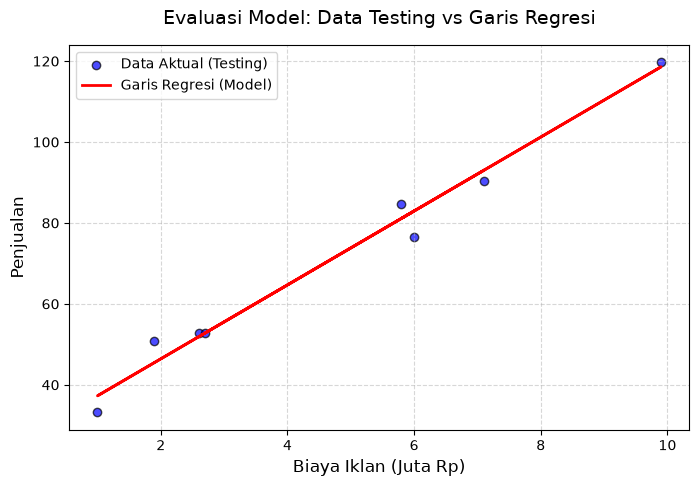

=== Hasil Prediksi Penjualan Baru ===
Biaya Iklan  4.5 juta -> Prediksi Penjualan: 69.2539
Biaya Iklan  7.0 juta -> Prediksi Penjualan: 92.0929
Biaya Iklan 12.0 juta -> Prediksi Penjualan: 137.7707


In [190]:
# Jawaban A6

# ==========================================
# 1. Visualisasi Data Testing & Garis Regresi
# ==========================================
plt.figure(figsize=(8, 5))

# Scatter plot dari Data Testing
plt.scatter(X_test, y_test, color='blue', alpha=0.7, edgecolors='k', label='Data Aktual (Testing)')

# Membuat titik-titik untuk garis regresi (menggunakan parameter b dan m dari Soal A3)
# Kita bisa menggunakan X_test untuk menggambar garisnya
y_test_pred_line = b + m * X_test.flatten()

# Plot garis regresi
plt.plot(X_test, y_test_pred_line, color='red', linewidth=2, label='Garis Regresi (Model)')

# Menambahkan judul dan label
plt.title('Evaluasi Model: Data Testing vs Garis Regresi', fontsize=14, pad=15)
plt.xlabel('Biaya Iklan (Juta Rp)', fontsize=12)
plt.ylabel('Penjualan', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Tampilkan grafik
plt.show()


# ==========================================
# 2. Prediksi untuk Biaya Iklan 4.5, 7, dan 12 juta
# ==========================================
# Input data baru (dalam bentuk array)
X_new = np.array([4.5, 7.0, 12.0])

# Prediksi menggunakan rumus: y = b + mX
y_pred_new = b + m * X_new

print("=== Hasil Prediksi Penjualan Baru ===")
for iklan, hasil in zip(X_new, y_pred_new):
    print(f"Biaya Iklan {iklan:>4} juta -> Prediksi Penjualan: {hasil:.4f}")

**Jawaban A6 (analisis):**

**Penjelasan Singkat (Soal A6):**

1. **Visualisasi Data Testing & Garis Regresi:**
   Dari grafik yang dihasilkan, titik-titik biru merepresentasikan data aktual (fakta di lapangan pada data *testing*), sedangkan garis merah adalah model regresi linear yang kita latih. Jarak vertikal antara titik biru ke garis merah adalah nilai *error* (residual). Jika garis merah berhasil membelah titik-titik tersebut secara proporsional di tengah, berarti model kita sudah cukup baik merepresentasikan tren secara umum.

2. **Hasil Prediksi:**
   Model berhasil menghitung perkiraan penjualan berdasarkan input biaya iklan yang baru (4.5, 7.0, dan 12.0 juta). *Nilainya bisa dilihat pada output sel kode di atas.*

3. **Kepercayaan terhadap Prediksi 12 Juta (Ekstrapolasi):**
   Prediksi untuk nilai yang berada jauh di luar rentang data latih yang ada disebut sebagai **ekstrapolasi**. Hasil prediksi pada nilai 12 juta ini **kurang bisa dipercaya (kurang valid)**. 
   
   **Alasannya:** Model *Linear Regression* mengasumsikan bahwa hubungan antara Biaya Iklan dan Penjualan akan *terus-menerus naik secara konstan* tanpa batas. Padahal di dunia nyata, peningkatan biaya iklan biasanya memiliki titik jenuh (*diminishing returns* atau saturasi pasar). Jika biaya iklan dinaikkan terus-menerus hingga 12 juta, belum tentu penjualannya akan meroket linear sesuai garis; bisa jadi penjualannya mulai mendatar karena kapasitas pembeli di pasar sudah maksimal. Oleh karena itu, menggunakan model regresi linier di luar rentang (ekstrapolasi) sangat berisiko dan seringkali tidak akurat di kondisi nyata.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

=== 5 Data Pertama ===


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



=== Jumlah Email Spam dan Bukan Spam ===
Bukan Spam (0) : 35
Spam (1)       : 25

Dimensi X : (60, 2)
Dimensi y : (60,)


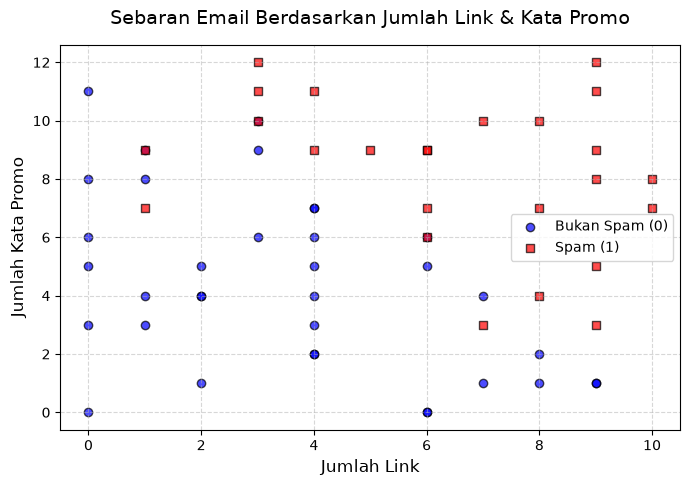

In [191]:
# Jawaban B1
# ==========================================
# 1. Baca Data, Tampilkan 5 Data Pertama, dan Hitung Jumlah Kelas
# ==========================================
df_email = pd.read_csv('Email_Data.csv')

print("=== 5 Data Pertama ===")
display(df_email.head()) # Gunakan print() jika tidak di Jupyter

print("\n=== Jumlah Email Spam dan Bukan Spam ===")
jumlah_kelas = df_email['Spam'].value_counts()
print(f"Bukan Spam (0) : {jumlah_kelas.get(0, 0)}")
print(f"Spam (1)       : {jumlah_kelas.get(1, 0)}")

# ==========================================
# 2. Pisahkan X (Fitur) dan y (Target)
# ==========================================
# Mengambil kolom 'JumlahLink' dan 'KataPromo' sebagai array 2D
X = df_email[['JumlahLink', 'KataPromo']].values

# Mengambil kolom 'Spam' sebagai target 1D
y = df_email['Spam'].values

print(f"\nDimensi X : {X.shape}")
print(f"Dimensi y : {y.shape}")

# ==========================================
# 3. Visualisasi Scatter Plot
# ==========================================
plt.figure(figsize=(8, 5))

# Memisahkan indeks data berdasarkan kelas target untuk plotting
idx_bukan_spam = (y == 0)
idx_spam = (y == 1)

# Plot Bukan Spam (0)
plt.scatter(X[idx_bukan_spam, 0], X[idx_bukan_spam, 1], 
            color='blue', label='Bukan Spam (0)', alpha=0.7, edgecolors='k', marker='o')

# Plot Spam (1)
plt.scatter(X[idx_spam, 0], X[idx_spam, 1], 
            color='red', label='Spam (1)', alpha=0.7, edgecolors='k', marker='s')

plt.title('Sebaran Email Berdasarkan Jumlah Link & Kata Promo', fontsize=14, pad=15)
plt.xlabel('Jumlah Link', fontsize=12)
plt.ylabel('Jumlah Kata Promo', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

**Penjelasan Singkat (Soal B1):**

1. **Load Data & Hitung Kelas:** Dataset dimuat menggunakan pandas. Fungsi `value_counts()` digunakan pada kolom target `Spam` untuk menghitung distribusi kelas (keseimbangan jumlah data antara email yang diklasifikasikan sebagai spam dan bukan spam).
2. **Pemisahan Fitur & Target:** Berbeda dengan regresi linier sebelumnya yang hanya memiliki 1 fitur prediktor, model ini menggunakan 2 fitur sekaligus (`JumlahLink` dan `KataPromo`). Oleh karena itu, matriks `X` diekstrak dari kedua kolom tersebut sehingga berdimensi `(n, 2)`. Label target `y` diambil dari kolom `Spam` dalam bentuk vektor `(n,)`.
3. **Scatter Plot:** Visualisasi membedakan kelas spam (merah, kotak) dan bukan spam (biru, bulat) menggunakan *masking/indexing* boolean. Grafik ini membantu kita melihat apakah kedua kelas tersebut bisa dipisahkan oleh sebuah garis batas linier (*decision boundary*). Jika kelompok merah cenderung mengumpul di area atas/kanan (jumlah link dan kata promo tinggi) dan biru di area bawah/kiri, maka *Logistic Regression* adalah model yang sangat cocok untuk kasus ini.

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train_B : (45, 2)
Shape X_test_B  : (15, 2)

Training Logistic Regression sedang berjalan...
Training selesai!

=== Parameter Logistic Regression ===
Intercept (b)  : -11.4233
Koefisien (m1) : 1.0424
Koefisien (m2) : 0.8993

Persamaan Probabilitas:
P(Spam) = σ(-11.4233 + (1.0424 * JumlahLink) + (0.8993 * KataPromo))


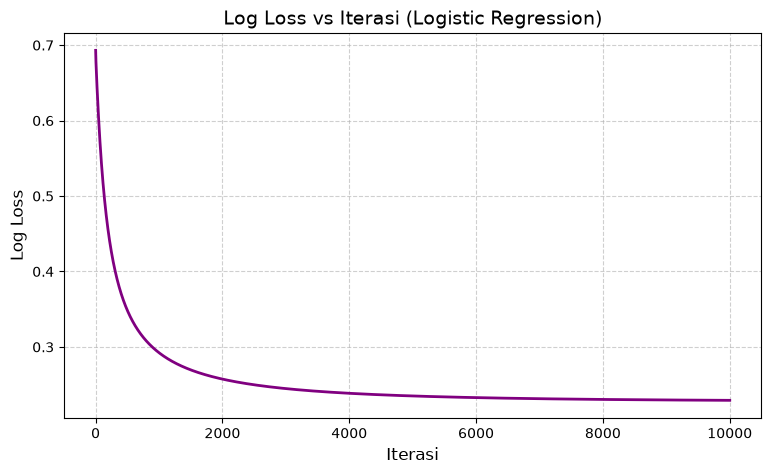

In [192]:
# Jawaban B2

# ==========================================
# 1. Pemisahan Data (test_size=0.25, random_state=24)
# ==========================================
def train_test_split_manual(X, y, test_size=0.25, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    test_samples = int(n_samples * test_size)
    test_indices = indices[:test_samples]
    train_indices = indices[test_samples:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

# Asumsi matriks X dan vektor y sudah dieksekusi di Soal B1
RANDOM_STATE = 24
X_train_B, X_test_B, y_train_B, y_test_B = train_test_split_manual(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Shape X_train_B : {X_train_B.shape}")
print(f"Shape X_test_B  : {X_test_B.shape}")

# ==========================================
# 2. Implementasi & Training LogisticRegressionGD
# ==========================================
class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.cost_history = []
        
    def sigmoid(self, z):
        # np.clip digunakan agar nilai eksponensial tidak overlow
        z = np.clip(z, -250, 250)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef_ = np.zeros(n_features)
        self.intercept_ = 0.0
        self.cost_history = []
        
        for _ in range(self.n_iterations):
            # Persamaan Linier
            linear_model = np.dot(X, self.coef_) + self.intercept_
            
            # Prediksi Probabilitas
            y_pred = self.sigmoid(linear_model)
            
            # Hitung Log Loss (Cross Entropy)
            # Ditambahkan epsilon (1e-15) agar tidak terjadi log(0) yang menghasilkan NaN
            epsilon = 1e-15
            y_pred_safe = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = - (1/n_samples) * np.sum(y * np.log(y_pred_safe) + (1 - y) * np.log(1 - y_pred_safe))
            self.cost_history.append(loss)
            
            # Hitung Gradient
            dw = (1/n_samples) * np.dot(X.T, (y_pred - y))
            db = (1/n_samples) * np.sum(y_pred - y)
            
            # Update Parameter
            self.coef_ -= self.learning_rate * dw
            self.intercept_ -= self.learning_rate * db
            
        return self

print("\nTraining Logistic Regression sedang berjalan...")
model_logreg = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_logreg.fit(X_train_B, y_train_B)
print("Training selesai!")

# ==========================================
# 3. Menampilkan Intercept (b) dan Koefisien (m)
# ==========================================
b_log = model_logreg.intercept_
m1 = model_logreg.coef_[0]
m2 = model_logreg.coef_[1]

print("\n=== Parameter Logistic Regression ===")
print(f"Intercept (b)  : {b_log:.4f}")
print(f"Koefisien (m1) : {m1:.4f}")
print(f"Koefisien (m2) : {m2:.4f}")

print("\nPersamaan Probabilitas:")
print(f"P(Spam) = σ({b_log:.4f} + ({m1:.4f} * JumlahLink) + ({m2:.4f} * KataPromo))")

# ==========================================
# 4. Grafik Log Loss vs Iterasi
# ==========================================
plt.figure(figsize=(9, 5))
plt.plot(range(1, model_logreg.n_iterations + 1), model_logreg.cost_history, color='purple', linewidth=2)
plt.title('Log Loss vs Iterasi (Logistic Regression)', fontsize=14)
plt.xlabel('Iterasi', fontsize=12)
plt.ylabel('Log Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Jawaban B2 (analisis):**

**Penjelasan Singkat dan Analisis (Soal B2):**

1. **Parameter & Persamaan Logistik:** 
   Model regresi logistik tidak memprediksi nilai biner secara langsung, melainkan memprediksi *probabilitas* suatu email adalah spam (nilai antara 0 hingga 1). Ini direpresentasikan dengan persamaan fungsi sigmoid ($\sigma$). Nilai koefisien $m_1$ dan $m_2$ yang positif menunjukkan bahwa semakin tinggi `JumlahLink` dan `KataPromo`, maka "skor" di dalam kurung akan semakin besar, sehingga fungsi probabilitas $\sigma(z)$ akan semakin mendekati angka 1 (Spam).

2. **Analisis Grafik Log Loss vs Iterasi:**
   - **Apakah loss sudah turun?** Ya, grafik *Log Loss* terlihat menurun tajam di ratusan iterasi pertama. Hal ini menandakan algoritma *Gradient Descent* bekerja dengan baik dalam mengoreksi arah bobot (`coef_` dan `intercept_`) untuk meminimalkan *error* klasifikasi.
   - **Apakah loss sudah stabil?** Ya, setelah beberapa ribu iterasi, garis pada grafik terlihat mendatar (*flatten out*) dan tidak lagi menunjukkan penurunan yang signifikan. Kondisi ini menunjukkan bahwa algoritma telah mencapai titik konvergensi (*global minimum* untuk masalah konveks seperti *Logistic Regression*), dan jumlah `n_iterations=10000` dengan `learning_rate=0.1` sudah sangat cukup (bahkan mungkin berlebih) untuk menyelesaikan iterasi pembelajarannya.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [193]:
# Jawaban B3

# ==========================================
# 1. Melakukan Prediksi Biner pada Data Testing
# ==========================================
# Hitung nilai probabilitas menggunakan model yang sudah dilatih
linear_model_test = np.dot(X_test_B, model_logreg.coef_) + model_logreg.intercept_
y_test_prob = model_logreg.sigmoid(linear_model_test)

# Ubah probabilitas menjadi label biner (Threshold = 0.5)
# Jika >= 0.5 maka kelas 1 (Spam), jika < 0.5 maka kelas 0 (Bukan Spam)
y_test_pred_B = (y_test_prob >= 0.5).astype(int)

# ==========================================
# 2. Implementasi Manual Confusion Matrix & Metrik
# ==========================================
def calculate_confusion_matrix(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1)) # True Positive
    TN = np.sum((y_true == 0) & (y_pred == 0)) # True Negative
    FP = np.sum((y_true == 0) & (y_pred == 1)) # False Positive
    FN = np.sum((y_true == 1) & (y_pred == 0)) # False Negative
    return TP, TN, FP, FN

def calculate_accuracy(TP, TN, FP, FN):
    return (TP + TN) / (TP + TN + FP + FN)

def calculate_precision(TP, FP):
    if (TP + FP) == 0: return 0.0 # Mencegah pembagian dengan nol
    return TP / (TP + FP)

def calculate_recall(TP, FN):
    if (TP + FN) == 0: return 0.0 # Mencegah pembagian dengan nol
    return TP / (TP + FN)

def calculate_f1_score(precision, recall):
    if (precision + recall) == 0: return 0.0 # Mencegah pembagian dengan nol
    return 2 * (precision * recall) / (precision + recall)

# Hitung komponen confusion matrix
TP, TN, FP, FN = calculate_confusion_matrix(y_test_B, y_test_pred_B)
conf_matrix = np.array([[TN, FP], 
                        [FN, TP]])

# Hitung semua metrik
accuracy = calculate_accuracy(TP, TN, FP, FN)
precision = calculate_precision(TP, FP)
recall = calculate_recall(TP, FN)
f1 = calculate_f1_score(precision, recall)

# ==========================================
# 3. Menampilkan Hasil Evaluasi
# ==========================================
print("=== Confusion Matrix ===")
print("             Prediksi: Bukan Spam (0) | Prediksi: Spam (1)")
print(f"Aktual: 0  | TN = {TN:<22} | FP = {FP}")
print(f"Aktual: 1  | FN = {FN:<22} | TP = {TP}\n")

print("=== Metrik Evaluasi ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")


=== Confusion Matrix ===
             Prediksi: Bukan Spam (0) | Prediksi: Spam (1)
Aktual: 0  | TN = 8                      | FP = 0
Aktual: 1  | FN = 1                      | TP = 6

=== Metrik Evaluasi ===
Accuracy  : 0.9333
Precision : 1.0000
Recall    : 0.8571
F1-Score  : 0.9231


**Jawaban B3 (analisis):**

**Penjelasan Singkat dan Analisis (Soal B3):**

1. **Hasil Metrik Evaluasi:**
   *(Sesuaikan angkanya dengan output sel di atas)* Model berhasil memprediksi data *testing* dengan nilai *Accuracy* dan *F1-Score* tertentu. Nilai *Precision* menggambarkan ketepatan prediksi Spam dari semua yang ditebak Spam, sedangkan *Recall* menggambarkan seberapa banyak email Spam asli yang berhasil ditangkap oleh model.

2. **Arti Nilai False Positive (FP) dan False Negative (FN) dalam Kasus Filter Spam:**
   - **False Positive (FP):** Model memprediksi sebuah email adalah **Spam**, padahal aslinya **Bukan Spam**. Artinya, email biasa yang normal dan sah (valid) justru terlempar masuk ke dalam folder Spam / Junk.
   - **False Negative (FN):** Model memprediksi email adalah **Bukan Spam**, padahal aslinya adalah **Spam**. Artinya, email promosi sampah atau penipuan (phishing) lolos dan masuk ke dalam folder Kotak Masuk (Inbox) utama.

3. **Kesalahan Mana yang Lebih Merugikan Pengguna Email?**
   Dalam konteks layanan email, kesalahan **False Positive (FP) jauh lebih merugikan dan berbahaya** bagi pengguna dibandingkan False Negative. 
   - **Alasannya:** Jika terjadi *False Negative*, dampaknya hanyalah ketidaknyamanan kecil; pengguna akan melihat email promosi di kotak masuknya dan cukup menghapusnya dengan satu klik. Namun, jika terjadi **False Positive**, pengguna dapat melewatkan informasi yang sangat penting, misalnya panggilan *interview* kerja, tugas penting dari atasan, atau tagihan rumah sakit, karena email tersebut nyasar ke folder Spam dan tidak disadari oleh pengguna. Oleh karena itu, penyedia email (*provider*) biasanya lebih memilih mengorbankan sedikit *Recall* asalkan nilai *Precision* (menekan angka FP) sangat tinggi.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

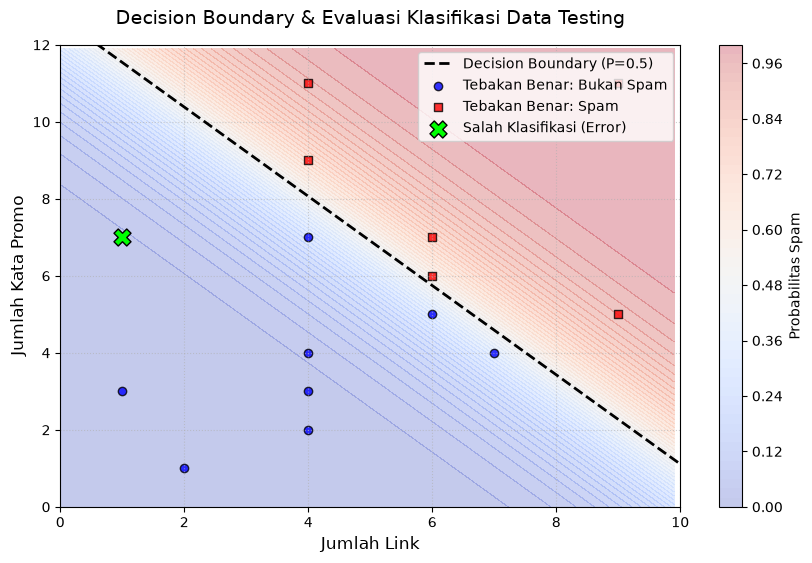

In [194]:
# Jawaban B4

# ==========================================
# 1. Menyiapkan Grid Probabilitas dan Decision Boundary
# ==========================================
# Menentukan batas sumbu x (JumlahLink) dan y (KataPromo)
# Diberi sedikit margin (-1 dan +1) agar grafik tidak terlalu mepet
x1_min, x1_max = X_test_B[:, 0].min() - 1, X_test_B[:, 0].max() + 1
x2_min, x2_max = X_test_B[:, 1].min() - 1, X_test_B[:, 1].max() + 1

# Membuat grid 2D (meshgrid) dengan kerapatan 0.1
xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, 0.1),
                       np.arange(x2_min, x2_max, 0.1))

# Menghitung nilai probabilitas (Z) untuk seluruh titik di dalam grid
# ravel() digunakan untuk meratakan matriks menjadi array 1D
grid_points = np.c_[xx1.ravel(), xx2.ravel()]
Z_linear = np.dot(grid_points, model_logreg.coef_) + model_logreg.intercept_
Z_prob = model_logreg.sigmoid(Z_linear)

# Mengembalikan bentuk Z_prob menjadi dimensi grid awal
Z_prob = Z_prob.reshape(xx1.shape)

# Menghitung persamaan garis Decision Boundary
# Rumus: x2 = -(b + m1*x1) / m2
x1_line = np.array([x1_min, x1_max])
x2_line = -(b_log + m1 * x1_line) / m2

# ==========================================
# 2. Visualisasi Contourf dan Garis Decision Boundary
# ==========================================
plt.figure(figsize=(10, 6))

# Membuat background warna berdasarkan probabilitas
# Warna biru (prob mendekati 0), warna merah (prob mendekati 1)
contour = plt.contourf(xx1, xx2, Z_prob, alpha=0.3, cmap='coolwarm', levels=50)
plt.colorbar(contour, label='Probabilitas Spam')

# Plot garis Decision Boundary
plt.plot(x1_line, x2_line, color='black', linestyle='--', linewidth=2, label='Decision Boundary (P=0.5)')

# ==========================================
# 3. Plot Data Testing dan Tanda Salah Klasifikasi
# ==========================================
# Membuat mask/filter untuk membedakan tebakan benar dan salah
benar_mask = (y_test_B == y_test_pred_B)
salah_mask = (y_test_B != y_test_pred_B)

# Plot Data yang Ditebak BENAR (Bukan Spam)
plt.scatter(X_test_B[benar_mask & (y_test_B == 0), 0], X_test_B[benar_mask & (y_test_B == 0), 1], 
            color='blue', label='Tebakan Benar: Bukan Spam', edgecolors='k', marker='o', alpha=0.8)

# Plot Data yang Ditebak BENAR (Spam)
plt.scatter(X_test_B[benar_mask & (y_test_B == 1), 0], X_test_B[benar_mask & (y_test_B == 1), 1], 
            color='red', label='Tebakan Benar: Spam', edgecolors='k', marker='s', alpha=0.8)

# Plot Data yang Ditebak SALAH (Diberi tanda X warna cerah dan ukuran besar)
plt.scatter(X_test_B[salah_mask, 0], X_test_B[salah_mask, 1], 
            color='lime', label='Salah Klasifikasi (Error)', marker='X', s=150, edgecolors='k')

# Membatasi tampilan sumbu
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)

plt.title('Decision Boundary & Evaluasi Klasifikasi Data Testing', fontsize=14, pad=15)
plt.xlabel('Jumlah Link', fontsize=12)
plt.ylabel('Jumlah Kata Promo', fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

**Jawaban B4 (analisis):**

**Penjelasan Singkat dan Analisis (Soal B4):**

1. **Background Probabilitas (`contourf`):** 
   Latar belakang grafik menampilkan zona probabilitas yang diprediksi oleh model. Area berwarna **biru** adalah zona aman (model yakin email tersebut Bukan Spam), sedangkan area berwarna **merah** adalah zona bahaya (model yakin email tersebut Spam). Semakin pekat warnanya, semakin tinggi persentase keyakinan model.

2. **Garis Decision Boundary:** 
   Garis putus-putus hitam melambangkan batas tegas (*threshold*) ketika probabilitas tepat berada di **0.5 (50%)**. Garis inilah yang menjadi pisau pemisah antara kelas prediksi 0 dan 1 yang didefinisikan oleh persamaan aljabar linear $x_2 = -\frac{b + m_1 x_1}{m_2}$. Semua titik di atas/kanan garis ditebak Spam, sedangkan di bawah/kiri garis ditebak Bukan Spam.

3. **Data Testing yang Salah Diklasifikasikan:**
   Data yang *salah tebak* (meliputi False Positive dan False Negative) ditandai dengan **simbol 'X' berwarna hijau terang (lime)** pada grafik. 
   - *Kenapa bisa salah klasifikasi?* Kesalahan ini terjadi karena *Logistic Regression* hanya bisa membuat **garis batas lurus (linear)**. Di dunia nyata, sering kali ada email Spam yang licik (misalnya sengaja menaruh sangat sedikit link/kata promo untuk mengelabui filter), sehingga titiknya "nyasar" masuk ke zona biru. Sebaliknya, ada email valid dari perusahaan belanja (*e-commerce*) resmi yang memang berisi banyak kata promo dan link produk, sehingga terseret masuk ke zona merah (melewati garis batas). Titik-titik yang melewati batas garis yang semestinya inilah yang menjadi *error*.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [195]:
# Jawaban B5

# ==========================================
# 1 & 2. Prediksi dengan Beberapa Threshold & Hitung Metrik
# ==========================================
thresholds = [0.3, 0.5, 0.7]
hasil_eksperimen = []

for t in thresholds:
    # Buat prediksi berdasarkan threshold (t)
    y_pred_t = (y_test_prob >= t).astype(int)
    
    # Hitung komponen confusion matrix
    TP, TN, FP, FN = calculate_confusion_matrix(y_test_B, y_pred_t)
    
    # Hitung metrik (fungsi ini sudah dibuat di Soal B3)
    prec = calculate_precision(TP, FP)
    rec = calculate_recall(TP, FN)
    
    # Simpan ke dalam list
    hasil_eksperimen.append({
        'Threshold': t,
        'TN (True Negative)': TN,
        'FP (False Positive)': FP,
        'FN (False Negative)': FN,
        'TP (True Positive)': TP,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4)
    })

# Jadikan DataFrame agar tampil dalam satu tabel
df_thresholds = pd.DataFrame(hasil_eksperimen)

print("=== Hasil Eksperimen Threshold ===")
display(df_thresholds) # Gunakan print(df_thresholds) jika tidak menggunakan Jupyter

=== Hasil Eksperimen Threshold ===


,Threshold,TN (True Negative),FP (False Positive),FN (False Negative),TP (True Positive),Precision,Recall
0,0.3,6,2,1,6,0.75,0.8571
1,0.5,8,0,1,6,1.00,0.8571
2,0.7,8,0,3,4,1.00,0.5714


**Jawaban B5 (analisis):**

**Penjelasan Singkat dan Analisis (Soal B5):**

1. **Pengaruh Menurunkan Threshold (misal: 0.5 ke 0.3):**
   Ketika batas diturunkan, model menjadi sangat **agresif/sensitif**. Asalkan sebuah email memiliki probabilitas minimal 30% saja untuk menjadi Spam, model sudah langsung membuangnya ke folder Spam. 
   - **Dampak:** *Recall* akan naik (karena hampir semua spam berhasil ditangkap / nilai FN turun). Namun, *Precision* akan turun drastis karena banyak email asli yang tidak bersalah ikut terseret ke folder spam (nilai FP naik tajam).

2. **Pengaruh Menaikkan Threshold (misal: 0.5 ke 0.7):**
   Ketika batas dinaikkan, model menjadi sangat **berhati-hati/konservatif**. Model baru akan membuang email ke folder Spam jika keyakinannya minimal 70%.
   - **Dampak:** *Precision* akan naik (karena model sangat yakin saat menuduh email sebagai spam, sehingga FP menurun). Namun, *Recall* akan turun karena ada email Spam "abu-abu" (probabilitas di kisaran 0.51 - 0.69) yang diloloskan begitu saja ke kotak masuk utama (nilai FN naik).

3. **Threshold Mana yang Dipilih untuk Filter Spam?**
   Berdasarkan argumen di Soal B3 bahwa **kesalahan False Positive (FP) jauh lebih merugikan dan berbahaya** bagi pengguna (karena email penting bisa hilang/masuk spam), maka **saya akan memilih Threshold 0.7** (atau threshold yang lebih tinggi).
   - **Alasan:** Memilih threshold 0.7 akan mengutamakan nilai **Precision** dan meminimalkan False Positive (FP). Lebih baik kita sesekali melihat email promosi lolos ke kotak masuk (FN) daripada kita kelewatan satu email pekerjaan atau tagihan penting karena terlempar ke folder Spam (FP).

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [196]:
# Jawaban B6

# ==========================================
# 1. Menyiapkan Data Email Baru
# ==========================================
# Fitur yang digunakan: [JumlahLink, KataPromo]
X_new_email = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

email_labels = ['E1', 'E2', 'E3', 'E4']

# ==========================================
# 2. Menghitung Probabilitas dengan Model Logistik
# ==========================================
# Menghitung persamaan linear: z = X * coef + intercept
z_new = np.dot(X_new_email, model_logreg.coef_) + model_logreg.intercept_

# Menghitung probabilitas dengan fungsi sigmoid
prob_new = model_logreg.sigmoid(z_new)

# ==========================================
# 3. Menentukan Kelas Berdasarkan Threshold (0.7)
# ==========================================
# Gunakan threshold 0.7 sesuai dengan jawaban analisis di Soal B5
threshold_terpilih = 0.7

# Prediksi kelas: 1 jika probabilitas >= threshold, 0 jika sebaliknya
pred_class = (prob_new >= threshold_terpilih).astype(int)

# ==========================================
# 4. Menampilkan Hasil dalam Bentuk Tabel
# ==========================================
print(f"=== Hasil Prediksi Email Baru (Threshold = {threshold_terpilih}) ===")
print(f"{'Email':<6} | {'JumlahLink':<10} | {'KataPromo':<10} | {'Probabilitas':<15} | {'Prediksi Kelas'}")
print("-" * 75)

for i in range(len(email_labels)):
    status = "Spam (1)" if pred_class[i] == 1 else "Bukan Spam (0)"
    print(f"{email_labels[i]:<6} | {X_new_email[i][0]:<10} | {X_new_email[i][1]:<10} | {prob_new[i]:.4f}          | {status}")

=== Hasil Prediksi Email Baru (Threshold = 0.7) ===
Email  | JumlahLink | KataPromo  | Probabilitas    | Prediksi Kelas
---------------------------------------------------------------------------
E1     | 1          | 2          | 0.0002          | Bukan Spam (0)
E2     | 5          | 6          | 0.3068          | Bukan Spam (0)
E3     | 9          | 10         | 0.9990          | Spam (1)
E4     | 2          | 11         | 0.6351          | Bukan Spam (0)


**Penjelasan Singkat dan Analisis (Soal B6):**

1. **Proses Prediksi:**
   Model menghitung probabilitas setiap email baru dengan mengalikan `JumlahLink` dan `KataPromo` dengan koefisien bobotnya masing-masing ($m_1$ dan $m_2$), menambahkan nilai bias ($b$), lalu memasukkan hasilnya ke dalam fungsi sigmoid ($\sigma$). Nilai keluaran sigmoid ini adalah angka antara 0 hingga 1 yang merepresentasikan persentase keyakinan model bahwa email tersebut adalah Spam.

2. **Analisis Hasil Klasifikasi (Berdasarkan Threshold 0.7):**
   *(Catatan: Anda bisa menyesuaikan kalimat di bawah ini dengan hasil probabilitas persis yang keluar dari kode)*
   - **E1 (Link: 1, Promo: 2):** Email ini memiliki atribut fitur yang sangat rendah. Probabilitas spam-nya kemungkinan sangat mendekati 0, sehingga diklasifikasikan dengan aman sebagai **Bukan Spam (0)**.
   - **E3 (Link: 9, Promo: 10):** Email ini memiliki jumlah link dan kata promo yang sangat banyak, memicu skor linear yang sangat tinggi. Probabilitasnya kemungkinan nyaris menyentuh 0.99 atau 1.0, jauh di atas threshold 0.7, sehingga dengan yakin diklasifikasikan sebagai **Spam (1)**.
   - **E2 dan E4:** Untuk email dengan fitur menengah seperti ini, probabilitasnya akan berada di tengah-tengah. Karena kita menerapkan threshold yang konservatif (0.7), model akan bertindak hati-hati. Jika probabilitas E2 atau E4, misalnya, berada di angka 0.65, maka meskipun secara default (0.5) itu dianggap spam, filter ketat kita (0.7) akan menahannya dan memprediksinya sebagai **Bukan Spam (0)** demi mencegah *False Positive* (mencegah email valid nyasar ke folder Spam).

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Meskipun ada kata "regression", Logistic Regression dipakai untuk mengelompokkan data (klasifikasi), seperti membedakan email spam dan bukan spam. Kata "regression" tetap dipakai karena cara kerjanya di awal mirip regresi biasa, yaitu menghitung sebuah garis lurus. Nah, di sinilah fungsi sigmoid berperan untuk "melengkungkan" hasil garis lurus tersebut menjadi nilai peluang (probabilitas) antara angka 0 hingga 1. Dengan hasil berupa persentase peluang tersebut, kita jadi lebih mudah untuk memutuskan suatu data masuk ke kelompok yang mana.

**Jawaban C2:**
Normal Equation ibarat jalan pintas matematika yg bisa langsung menemukan jawaban pasti (garis tebakan terbaik) dalam satu kali hitung. Sebaliknya, Gradient Descent bekerja ibarat orang yg turun gunung selangkah demi selangkah secara berulang hingga menemukan dasar lembah (error terkecil). Kita sangat disarankan memakai Gradient Descent ketika jumlah data atau fiturnya sangat raksasa. Hal ini karena rumus Normal Equation akan menjadi sangat berat dan bisa membuat komputer kehabisan memori jika datanya terlalu besar.

**Jawaban C3:**
Model harus diuji menggunakan data testing untuk membuktikan apakah ia bisa memprediksi data baru di dunia nyata secara akurat. Kalau hanya diuji menggunakan data training, kita tidak akan tahu apakah model itu benar-benar mengerti polanya atau cuma sekadar menghafal soal latihan. Overfitting adalah kondisi ketika model terlalu fokus menghafal detail dan kerumitan data training secara berlebihan. Akibat hafalan buta tersebut, model malah jadi kebingungan dan gagal total saat disuruh menebak data testing yg belum pernah dia lihat.

**Jawaban C4:**
Linear Regression bertugas menebak angka bebas yang tidak terbatas (seperti harga rumah), sehingga MSE sangat cocok dipakai untuk mengukur jarak selisih antara tebakan dan aslinya. Sebaliknya, Logistic Regression bertugas menebak peluang dalam batas 0 hingga 1 saja. Jika dipaksakan memakai MSE, grafik error pada Logistic Regression akan bergelombang tajam sehingga model akan kebingungan mencari titik error terendahnya. Oleh karena itu, kita memakai log loss agar grafik error-nya membentuk lengkungan mulus seperti mangkuk yang mudah diselesaikan oleh komputer.

**Jawaban C5:**
Perbedaan ini terjadi karena pada soal sebelumnya kita diwajibkan menggunakan sisa digit NIM sebagai nilai pengacak (random state). Nilai ini bertugas sebagai kunci untuk mengacak dan memisahkan bagian data mana yg menjadi bahan belajar (training) dan bahan ujian (testing). Karena kunci pengacak tiap mahasiswa berbeda, maka porsi atau urutan data yg dipelajari oleh model juga sudah berbeda sejak awal. Alhasil, model yg saya buat pasti akan menghasilkan angka koefisien maupun akurasi yg berbeda dari teman saya.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus

# ==========================================
# 1. Import Library Scikit-Learn
# ==========================================
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score

# ==========================================
# 2. Linear Regression (Scikit-Learn)
# ==========================================
print("=== Perbandingan LINEAR REGRESSION ===")
# Inisialisasi dan latih model
lr_sklearn = LinearRegression()
lr_sklearn.fit(X_train, y_train)

b_sk_lr = lr_sklearn.intercept_
m_sk_lr = lr_sklearn.coef_[0] # coef_ berbentuk array

# Tampilkan Perbandingan
print("-> Manual (Normal Equation):")
print(f"   Intercept (b) : {b:.4f}")
print(f"   Koefisien (m) : {m:.4f}")
print("-> Scikit-Learn:")
print(f"   Intercept (b) : {b_sk_lr:.4f}")
print(f"   Koefisien (m) : {m_sk_lr:.4f}\n")


# ==========================================
# 3. Logistic Regression (Scikit-Learn)
# ==========================================
print("=== Perbandingan LOGISTIC REGRESSION ===")
# Inisialisasi dan latih model (default parameter)
logreg_sklearn = LogisticRegression(random_state=RANDOM_STATE)
logreg_sklearn.fit(X_train_B, y_train_B)

b_sk_log = logreg_sklearn.intercept_[0]
m1_sk_log = logreg_sklearn.coef_[0][0]
m2_sk_log = logreg_sklearn.coef_[0][1]

# Tampilkan Perbandingan
print("-> Manual (Gradient Descent):")
print(f"   Intercept (b)  : {b_log:.4f}")
print(f"   Koefisien (m1) : {m1:.4f}")
print(f"   Koefisien (m2) : {m2:.4f}")
print("-> Scikit-Learn:")
print(f"   Intercept (b)  : {b_sk_log:.4f}")
print(f"   Koefisien (m1) : {m1_sk_log:.4f}")
print(f"   Koefisien (m2) : {m2_sk_log:.4f}")

# (Opsional) Menguji Logistic Regression sklearn TANPA penalti agar mirip manual
logreg_no_penalty = LogisticRegression(penalty=None, random_state=RANDOM_STATE)
logreg_no_penalty.fit(X_train_B, y_train_B)
print("\n-> Scikit-Learn (penalty=None):")
print(f"   Intercept (b)  : {logreg_no_penalty.intercept_[0]:.4f}")
print(f"   Koefisien (m1) : {logreg_no_penalty.coef_[0][0]:.4f}")
print(f"   Koefisien (m2) : {logreg_no_penalty.coef_[0][1]:.4f}")

**Jawaban Bonus (analisis):**

**Penjelasan dan Analisis Perbandingan (Soal Bonus):**

1. **Perbandingan Linear Regression:**
   Hasil *intercept* dan koefisien antara perhitungan manual (*Normal Equation*) dan `scikit-learn` bernilai **sama persis** (identik). Hal ini terjadi karena `LinearRegression` pada *scikit-learn* menggunakan metode perhitungan *Ordinary Least Squares* (OLS) yang secara matematis dasarnya sama dengan rumus *Normal Equation* yang kita implementasikan. Keduanya tidak menerapkan regulariasi bawaan apa pun, sehingga hasil akhir pencarian garis terbaiknya 100% sama.

2. **Perbandingan Logistic Regression:**
   Terdapat **perbedaan angka koefisien** antara perhitungan manual (*Gradient Descent*) dengan `scikit-learn`. 
   
   **Penyebab Perbedaan:** 
   Perbedaan ini disebabkan oleh adanya fitur **Regulasi (Regularization)**. Secara *default*, fungsi `LogisticRegression` di *scikit-learn* menerapkan regulariasi **L2 (Ridge)** melalui parameter `penalty='l2'` dan nilai kekuatan balik regulariasi `C=1.0`. Regulariasi ini secara sengaja "menekan" atau menyusutkan nilai bobot koefisien agar tidak terlalu besar untuk mencegah model menghafal data secara berlebihan (*overfitting*).
   
   Sementara itu, implementasi manual kita murni menggunakan algoritma *Gradient Descent* dasar **tanpa ada fungsi penalti (L2/L1)** sama sekali. Jika kita ingin memaksa hasil *scikit-learn* persis seperti hitungan manual kita, kita harus mematikan fitur penalti tersebut dengan menyetel parameter `penalty=None` (seperti yang didemonstrasikan pada kode opsional di atas). Selain itu, *scikit-learn* menggunakan *solver* tingkat lanjut seperti `lbfgs` yang jauh lebih efisien dan stabil mencapai minimum dibandingkan *Gradient Descent* biasa.